In [1]:
#q1
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial intelligence is changing the world.
It helps people solve problems and automate tasks.
Machine learning allows computers to learn from data.
AI is used in healthcare, education, and transportation.
I enjoy learning about AI because it makes technology smarter."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:", words)
print("\nSentence Tokens:", sentences)

print("\nUsing split():", text.split())
print("\nUsing word_tokenize():", word_tokenize(text))

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nWords after removing stopwords:", filtered_words)

frequency = Counter(filtered_words)
print("\nWord Frequency Distribution:", frequency)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Cleaned Text:
 artificial intelligence is changing the world
it helps people solve problems and automate tasks
machine learning allows computers to learn from data
ai is used in healthcare education and transportation
i enjoy learning about ai because it makes technology smarter

Word Tokens: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'problems', 'and', 'automate', 'tasks', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'makes', 'technology', 'smarter']

Sentence Tokens: ['Artificial intelligence is changing the world.', 'It helps people solve problems and automate tasks.', 'Machine learning allows computers to learn from data.', 'AI is used in healthcare, education, and transportation.', 'I enjoy learning about AI because it makes technology smarter.']

Using split()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [2]:
#q2
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial intelligence is changing the world.
It helps people solve problems and automate tasks.
Machine learning allows computers to learn from data.
AI is used in healthcare, education, and transportation.
I enjoy learning about AI because it makes technology smarter."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:", words)

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print("\nAfter Stopword Removal:", filtered_words)

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]
print("\nStemmed Words:", stemmed_words)

lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]
print("\nLemmatized Words:", lemmatized_words)

print("\nComparison:")
print("Stemming may produce non-dictionary words.")
print("Lemmatization produces meaningful base forms.")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'problems', 'and', 'automate', 'tasks', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'makes', 'technology', 'smarter']

After Stopword Removal: ['artificial', 'intelligence', 'changing', 'world', 'helps', 'people', 'solve', 'problems', 'automate', 'tasks', 'machine', 'learning', 'allows', 'computers', 'learn', 'data', 'ai', 'used', 'healthcare', 'education', 'transportation', 'enjoy', 'learning', 'ai', 'makes', 'technology', 'smarter']

Stemmed Words: ['artifici', 'intellig', 'chang', 'world', 'help', 'peopl', 'solv', 'problem', 'autom', 'task', 'machin', 'learn', 'allow', 'comput', 'learn', 'data', 'ai', 'use', 'healthcar', 'educ', 'transport', 'enjoy', 'learn', 'ai', 'make', 'technolog', 'smarter']

Lemm

In [3]:
#q3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

texts = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Machine learning improves artificial intelligence applications.",
    "Deep learning uses neural networks to analyze complex data."
]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

feature_names = tfidf_vectorizer.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nText {i + 1}: {text}")
    print("Top 3 Keywords:")

    for index in top_indices:
        print(feature_names[index], ":", round(scores[index], 3))


Vocabulary:
['analyze' 'and' 'applications' 'artificial' 'complex' 'computers' 'data'
 'deep' 'helps' 'improves' 'intelligence' 'learn' 'learning' 'machine'
 'networks' 'neural' 'problems' 'solve' 'to' 'uses']

Bag of Words Matrix:
[[0 1 0 1 0 1 0 0 1 0 1 1 0 0 0 0 1 1 0 0]
 [0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 0 0 0 0]
 [1 0 0 0 1 0 1 1 0 0 0 0 1 0 1 1 0 0 1 1]]

TF-IDF Matrix:
[[0.    0.374 0.    0.284 0.    0.374 0.    0.    0.374 0.    0.284 0.374
  0.    0.    0.    0.    0.374 0.374 0.    0.   ]
 [0.    0.    0.46  0.349 0.    0.    0.    0.    0.    0.46  0.349 0.
  0.349 0.46  0.    0.    0.    0.    0.    0.   ]
 [0.341 0.    0.    0.    0.341 0.    0.341 0.341 0.    0.    0.    0.
  0.26  0.    0.341 0.341 0.    0.    0.341 0.341]]

Text 1: Artificial intelligence helps computers learn and solve problems.
Top 3 Keywords:
problems : 0.374
solve : 0.374
learn : 0.374

Text 2: Machine learning improves artificial intelligence applications.
Top 3 Keywords:
improves : 0.46
application

In [4]:
#q4
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence enables machines to learn from data.
AI systems solve problems and automate intelligent tasks.
Machine learning improves prediction and decision making.
AI is widely used in healthcare and education.
"""

text2 = """
Blockchain stores information in distributed digital ledgers.
Blockchain technology provides security and transparency.
It records transactions across a network of computers.
Blockchain is widely used in digital currencies and finance.
"""

def preprocess(text):
    return re.findall(r'\b[a-z]+\b', text.lower())

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("AI Tokens:", tokens1)
print("Blockchain Tokens:", tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)
print("\nJaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(
    tfidf_matrix[0:1], tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nAnalysis:")
print("Jaccard measures overlap between unique words.")
print("Cosine measures similarity between TF-IDF vectors.")
print("Cosine considers the weights of words.")


AI Tokens: ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'solve', 'problems', 'and', 'automate', 'intelligent', 'tasks', 'machine', 'learning', 'improves', 'prediction', 'and', 'decision', 'making', 'ai', 'is', 'widely', 'used', 'in', 'healthcare', 'and', 'education']
Blockchain Tokens: ['blockchain', 'stores', 'information', 'in', 'distributed', 'digital', 'ledgers', 'blockchain', 'technology', 'provides', 'security', 'and', 'transparency', 'it', 'records', 'transactions', 'across', 'a', 'network', 'of', 'computers', 'blockchain', 'is', 'widely', 'used', 'in', 'digital', 'currencies', 'and', 'finance']

Jaccard Similarity: 0.1042
Cosine Similarity: 0.1636

Analysis:
Jaccard measures overlap between unique words.
Cosine measures similarity between TF-IDF vectors.
Cosine considers the weights of words.



Review: This laptop is excellent and works very smoothly.
Polarity: 0.76
Subjectivity: 0.825
Sentiment: Positive

Review: The battery is terrible and the laptop is very slow.
Polarity: -0.695
Subjectivity: 0.76
Sentiment: Negative

Review: The laptop is okay and has average performance.
Polarity: 0.175
Subjectivity: 0.45
Sentiment: Positive


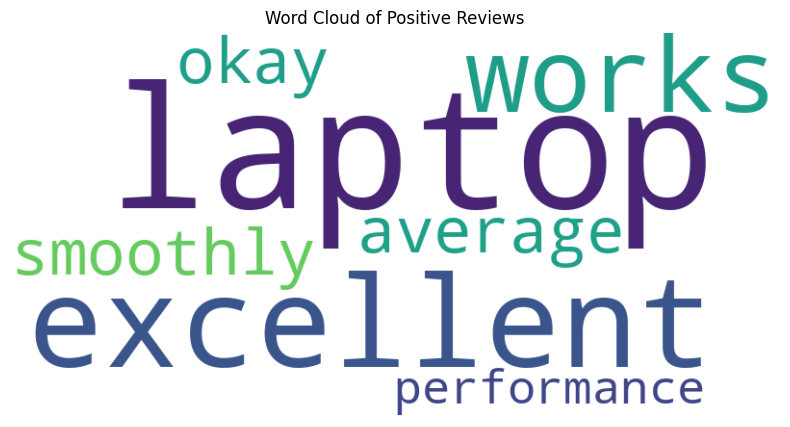

In [5]:
#q5
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This laptop is excellent and works very smoothly.",
    "The battery is terrible and the laptop is very slow.",
    "The laptop is okay and has average performance."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()


In [6]:
#q6
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Technology is changing the way people live and work.
Artificial intelligence helps computers learn from data and solve problems.
Machine learning is used in healthcare, education, business, and science.
Students use technology to study, communicate, and develop new skills.
Programming teaches logical thinking and helps people build useful applications.
Data plays an important role in modern computer systems.
Neural networks can recognize patterns and make predictions.
Deep learning is a powerful branch of machine learning.
Computers process information quickly and perform repetitive tasks efficiently.
Technology continues to create new opportunities for innovation.
Learning computer science helps students understand digital systems.
Artificial intelligence and data science are important fields.
They can improve productivity and support better decisions.
The future of technology depends on creativity and responsible innovation.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1

input_sequences = []

for line in text.lower().split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = tf.keras.utils.to_categorical(
    y, num_classes=total_words
)

model = Sequential([
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=100, verbose=0)
print("Model training completed.")

def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_index = int(np.argmax(predicted, axis=1)[0])

        output_word = None
        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                output_word = word
                break

        if output_word is None:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")
print("1.", generate_text("technology", 10))
print("2.", generate_text("artificial intelligence", 10))
print("3.", generate_text("machine learning", 10))


Model training completed.

Generated Text:
1. technology is is the way people live and work work problems
2. artificial intelligence helps helps learn from data and solve problems applications efficiently
3. machine learning is used in healthcare education business and science science science
